# Neutrino energies from Callan–Rubakov catalysis by a relativistic monopole

**Question (Daniele, Nov 2026):** what is the energy of the neutrinos produced by monopole catalysis, as a function of the monopole kinetic energy $E_M$, channel by channel? Benchmark $E_M = 10^{11}$ GeV.

**Why it matters for the draft:** Sect. 2.1 / Eq. 5 of *MM 200 PeV nu* assumes the catalysis products decay **at rest in the monopole frame**, $E_\nu^{(0)}\simeq 30$–$50$ MeV, and then boosts by $\gamma_M$. That is the $\beta_M\to 0$ picture (monopole trapped in the Sun). For a monopole with $\gamma_M\sim10^9$ the target proton carries $\gamma_M m_p\sim10^9$ GeV in the monopole frame, which is far more than the monopole mass in the paper's window ($m_M=10^2$–$10^5$ GeV): the monopole frame is **not** the centre-of-mass frame and the products are not at rest in it.

This notebook does the kinematics with Lorentz invariants only:

* **Stage 1 (vertex)** $M+t\to M+W$, target $t=p$ or $e^-$ at rest in the lab, $W$ = light final-state system ($e^+\pi^0$, $\bar p\pi^+\pi^-$, ...).  
  $s = m_M^2+m_t^2+2E_M^{\rm tot}m_t$, $\;\gamma_{cm}=(E_M^{\rm tot}+m_t)/\sqrt s$.  
  The Callan–Rubakov amplitude is pure lowest partial wave; for the minimal monopole $q_J=1/2$ it is **isotropic in the CM frame** (Candela, Khoze, Turner 2504.14918 Eq. 2.3 & 2.5; Khoze 2405.18689 Eq. 6.5 & 6.12). $W$ then decays with flat phase space.
* **Stage 2 (chains)** $\pi^\pm,K,\mu$ decay in flight (ISM: nothing is absorbed; Pedro, 2 Nov: in the atmosphere/detector they do **not** decay, so there only prompt neutrinos count).

Analytic content of Stage 1 (two-body $M+W$):

$$E_W^{\rm lab}(\theta_{cm}) = \gamma_{cm}\left(E_W^* - \beta_{cm}\,p^*\cos\theta_{cm}\right),\qquad
\langle E_W^{\rm lab}\rangle_{\rm iso}=\gamma_{cm}E_W^*$$

| regime | $\langle E_W^{\rm lab}\rangle$ | comment |
|---|---|---|
| light MM, $m_M\ll\sqrt{2E_Mm_t}$ | $\simeq E_M/2$, flat between $\sim m_W^2/2m_t$ and $\sim E_M$ | independent of $m_M$ |
| heavy MM, $m_M\gg\sqrt{2E_Mm_t}$ | $\simeq\gamma_M^2 m_t$ | relativistic mirror |
| $\beta_M\to0$ | $m_t$ shared among products | the draft's Eq. 5 picture |

Forward scattering of the MM ($\theta_{cm}=0$) gives the minimum $E_W^{\rm lab}\simeq m_W^2/(2m_t)$; for $M e^-\to M\bar p$ this is Candela's 861 GeV plateau.

Module: `mm_kinematics.py` (same folder).

In [1]:
import importlib, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, '../src')
import mm_kinematics as mk; importlib.reload(mk)
pd.set_option('display.width', 200); pd.set_option('display.float_format', '{:.3g}'.format); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

E_BENCH = 1e11                      # GeV, Daniele's benchmark kinetic energy
M_GRID  = [1e2, 1e3, 1e4, 1e5]      # GeV, the draft's mass window
E_KM3   = 2.2e8                     # GeV, 220 PeV
CH_MAIN = ['p -> e+ pi0', 'p -> e+ pi+ pi-', 'p -> mu+ K0', 'p -> nubar_e pi+', 'e- -> pbar pi+ pi-', 'e- -> pbar K0']
N_BENCH, N_SCAN = 200_000, 40_000
mp, me = mk.MASS['p'], mk.MASS['e-']

/home/carlo/.local/lib/python3.11/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/carlo/.local/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


## 1. Frames and analytic limits at the benchmark

In [2]:
rows = []
for tgt, mt in (('p', mp), ('e-', me)):
    for mM in M_GRID + [1e9, 1e16]:
        fr = mk.cm_frame(E_BENCH, mM, mt)
        gM = 1 + E_BENCH/mM
        lim = mk.analytic_limits(E_BENCH, mM, mt, mW=1.2 if tgt=='p' else 1.5)
        rows.append(dict(target=tgt, m_M=mM, gamma_M=gM, sqrt_s_GeV=fr['sqrt_s'], gamma_cm=fr['gamma_cm'],
                         E_W_forward=lim['forward'], E_W_mean=lim['mean'], E_W_backward=lim['backward'],
                         draft_Enu_lo=mk.draft_estimate(E_BENCH, mM)[0], draft_Enu_hi=mk.draft_estimate(E_BENCH, mM)[1]))
frames = pd.DataFrame(rows)
frames

,target,m_M,gamma_M,sqrt_s_GeV,gamma_cm,E_W_forward,E_W_mean,E_W_backward,draft_Enu_lo,draft_Enu_hi
0,p,100,1e+09,4.33e+05,2.31e+05,1.24,5e+10,1e+11,3e+07,5e+07
1,p,1e+03,1e+08,4.33e+05,2.31e+05,1.24,5e+10,1e+11,3e+06,5e+06
2,p,1e+04,1e+07,4.33e+05,2.31e+05,1.24,5e+10,9.99e+10,3e+05,5e+05
3,p,1e+05,1e+06,4.45e+05,2.25e+05,1.24,4.75e+10,9.49e+10,3e+04,5e+04
4,p,1e+09,101,1e+09,101,1.24,9.57e+03,1.91e+04,3.03,5.05
5,p,1e+16,1,1e+16,1,1.53,0.938,0.938,0.03,0.05
6,e-,100,1e+09,1.01e+04,9.89e+06,2.2e+03,5e+10,1e+11,3e+07,5e+07
7,e-,1e+03,1e+08,1.02e+04,9.84e+06,2.2e+03,4.95e+10,9.9e+10,3e+06,5e+06
8,e-,1e+04,1e+07,1.42e+04,7.03e+06,2.2e+03,2.53e+10,5.05e+10,3e+05,5e+05
9,e-,1e+05,1e+06,1.01e+05,9.95e+05,2.2e+03,5.06e+08,1.01e+09,3e+04,5e+04


For every mass in the draft's window the light system takes on average **half of the monopole energy** when the target is a proton. With an electron target the same holds up to $m_M\sim10^3$ GeV; at $m_M = 10^5$ GeV the electron channel is close to threshold ($\sqrt s\simeq m_M$) and the products get $\sim\gamma_M^2 m_e$. The last two columns are what the draft's Eq. 5 would give: several orders of magnitude lower.

## 2. Channels

Proton-initiated (Super-K 1203.0940 Eq. 1; Hu et al. 2201.02386 Eq. 3.2) and electron-initiated (Candela et al. Eq. 2.2; Daniele: take $\bar p\pi^+\pi^-$ and $\bar pK^0$). Branching ratios are the literature values for slow monopoles; for $\beta_M>0.2$ the proton channels carry the geometric suppression $\xi=(m_p/m_M)^2$ (Khoze Sect. 6.2), the electron channels do not.

In [3]:
chan_rows = [
 ('p -> e+ pi0',        'p',  'e+ pi0',         '~0.5 of e+ pi~',   'none (pi0 -> gamma gamma)'),
 ('p -> e+ pi+ pi-',    'p',  'e+ (rho0,eta,omega) -> e+ pi+ pi-', '~0.5 of e+ pi~', 'pi+ -> mu+ nu_mu, mu+ -> e+ nu_e nubar_mu, and c.c. for pi-'),
 ('p -> mu+ K0',        'p',  'mu+ K0',         '1/400 - 1/2 of e+ pi~', 'mu+ chain; K_S -> pi pi; K_L -> pi l nu'),
 ('p -> nubar_e pi+',   'p',  'nubar_e pi+',    '~1e-4',            'PROMPT nubar_e + pi+ chain'),
 ('e- -> pbar pi+ pi-', 'e-', 'pbar pi+ pi-',   'see Candela Eq.2.3','pi+ and pi- chains (pbar stable)'),
 ('e- -> pbar K0',      'e-', 'pbar K0',        'see Candela Eq.2.3','K0 chain (pbar stable)'),
]
chans = pd.DataFrame(chan_rows, columns=['channel','target','light system W','branching (slow MM)','neutrino sources'])
chans['xi = (m_p/m_M)^2 at m_M = 1e2 / 1e5 GeV'] = ['%.0e / %.0e' % ((mp/1e2)**2, (mp/1e5)**2) if t=='p' else '1 / 1' for t in chans.target]
chans

,channel,target,light system W,branching (slow MM),neutrino sources,xi = (m_p/m_M)^2 at m_M = 1e2 / 1e5 GeV
0,p -> e+ pi0,p,e+ pi0,~0.5 of e+ pi~,none (pi0 -> gamma gamma),9e-05 / 9e-11
1,p -> e+ pi+ pi-,p,"e+ (rho0,eta,omega) -> e+ pi+ pi-",~0.5 of e+ pi~,"pi+ -> mu+ nu_mu, mu+ -> e+ nu_e nubar_mu, and...",9e-05 / 9e-11
2,p -> mu+ K0,p,mu+ K0,1/400 - 1/2 of e+ pi~,mu+ chain; K_S -> pi pi; K_L -> pi l nu,9e-05 / 9e-11
3,p -> nubar_e pi+,p,nubar_e pi+,~1e-4,PROMPT nubar_e + pi+ chain,9e-05 / 9e-11
4,e- -> pbar pi+ pi-,e-,pbar pi+ pi-,see Candela Eq.2.3,pi+ and pi- chains (pbar stable),1 / 1
5,e- -> pbar K0,e-,pbar K0,see Candela Eq.2.3,K0 chain (pbar stable),1 / 1


## 3. Benchmark: $E_M = 10^{11}$ GeV

Per channel, per flavour and per monopole mass: neutrinos per catalysis, mean / median / 10–90 % range of $E_\nu$ (all decays in flight = ISM case). Light-system invariant mass $m_W=\sum m_i+Q$, $Q\sim U(0,1\ {\rm GeV})$.

In [4]:
bench = {}
rows = []
for ch in CH_MAIN:
    for mM in M_GRID:
        r = mk.catalysis(ch, E_BENCH, mM, n=N_BENCH, seed=7)
        bench[(ch, mM)] = r
        if r is None:
            rows.append(dict(channel=ch, m_M=mM, flavour='all', closed=True)); continue
        for f, v in mk.summarize(r).items():
            rows.append(dict(channel=ch, m_M=mM, flavour=f, **v))
bench_df = pd.DataFrame(rows)
bench_df.to_csv('../results/benchmark_E1e11.csv', index=False)
show = bench_df[bench_df.flavour=='all'].pivot(index='channel', columns='m_M', values=['mult','median','mean','p10','p90'])
show

mult                     median                                mean                                 p10                                 p90                           
m_M                100   1e+03 1e+04 1e+05    100      1e+03    1e+04    1e+05    100      1e+03    1e+04    1e+05    100      1e+03    1e+04    1e+05    100      1e+03    1e+04    1e+05
channel                                                                                                                                                                                   
e- -> pbar K0       4.08  4.08  4.08  4.08 1.23e+09 1.22e+09 6.22e+08 1.25e+07 2.55e+09 2.53e+09 1.29e+09 2.58e+07  1.1e+08 1.09e+08 5.54e+07 1.11e+06 6.56e+09  6.5e+09 3.32e+09 6.64e+07
e- -> pbar pi+ pi-     6     6     6     6 1.22e+09 1.21e+09 6.18e+08 1.24e+07 2.35e+09 2.33e+09 1.19e+09 2.38e+07 1.12e+08 1.11e+08 5.65e+07 1.13e+06 5.99e+09 5.93e+09 3.03e+09 6.06e+07
p -> e+ pi+ pi-        6     6     6     6 2.55e+09 2.55e+09 2.55e+09 2.42e+09 4.57e+09 4.57e+09 4.57e+09 4.34e+09 2.35e+08 2.35e+08 2.35e+08 2.23e+08 1.17e+10 1.17e+10 1.17e+10 1.11e+10
p -> e+ pi0            0     0     0     0      NaN      NaN      NaN      NaN      NaN      NaN      NaN      NaN      NaN      NaN      NaN      NaN      NaN      NaN      NaN      NaN
p -> mu+ K0         6.08  6.08  6.08  6.08 2.25e+09 2.25e+09 2.25e+09 2.14e+09 4.62e+09 4.62e+09 4.62e+09 4.39e+09 1.97e+08 1.97e+08 1.97e+08 1.87e+08 1.21e+10 1.21e+10  1.2e+10 1.14e+10
p -> nubar_e pi+       4     4     4     4 5.23e+09 5.23e+09 5.22e+09 4.96e+09 1.06e+10 1.06e+10 1.06e+10    1e+10 4.34e+08 4.34e+08 4.34e+08 4.12e+08  2.8e+10  2.8e+10  2.8e+10 2.66e+10

In [5]:
# per-flavour detail at m_M = 1e3 GeV
d = bench_df[(bench_df.m_M==1e3)].set_index(['channel','flavour'])[['mult','mean','median','p10','p90']]
d

mult     mean   median      p10      p90
channel            flavour                                           
p -> e+ pi0        nu_e         0      NaN      NaN      NaN      NaN
                   nubar_e      0      NaN      NaN      NaN      NaN
                   nu_mu        0      NaN      NaN      NaN      NaN
                   nubar_mu     0      NaN      NaN      NaN      NaN
                   all          0      NaN      NaN      NaN      NaN
p -> e+ pi+ pi-    nu_e         1 4.46e+09  2.4e+09 2.16e+08 1.15e+10
                   nubar_e      1 4.46e+09 2.42e+09 2.17e+08 1.15e+10
                   nu_mu        2 4.63e+09 2.62e+09 2.45e+08 1.17e+10
                   nubar_mu     2 4.62e+09 2.62e+09 2.46e+08 1.17e+10
                   all          6 4.57e+09 2.55e+09 2.35e+08 1.17e+10
p -> mu+ K0        nu_e      1.75 5.01e+09 2.44e+09 2.04e+08 1.32e+10
                   nubar_e  0.748 4.11e+09 1.96e+09 1.73e+08 1.07e+10
                   nu_mu     1.29 3.73e+09 1.94e+09 1.79e+08 9.58e+09
                   nubar_mu  2.29 4.98e+09 2.44e+09 2.14e+08  1.3e+10
                   all       6.08 4.62e+09 2.25e+09 1.97e+08 1.21e+10
p -> nubar_e pi+   nu_e         1 6.64e+09  3.6e+09 3.13e+08 1.73e+10
                   nubar_e      1  2.2e+10 1.58e+10 1.63e+09 5.27e+10
                   nu_mu        1    6e+09  3.6e+09 3.31e+08 1.54e+10
                   nubar_mu     1 7.71e+09 4.24e+09 3.67e+08 2.01e+10
                   all          4 1.06e+10 5.23e+09 4.34e+08  2.8e+10
e- -> pbar pi+ pi- nu_e         1 2.27e+09 1.15e+09 1.02e+08 5.82e+09
                   nubar_e      1 2.28e+09 1.14e+09 1.02e+08 5.83e+09
                   nu_mu        2 2.36e+09 1.24e+09 1.16e+08 5.98e+09
                   nubar_mu     2 2.36e+09 1.25e+09 1.15e+08 5.99e+09
                   all          6 2.33e+09 1.21e+09 1.11e+08 5.93e+09
e- -> pbar K0      nu_e     0.748  2.7e+09 1.23e+09 1.07e+08    7e+09
                   nubar_e  0.748 2.68e+09 1.23e+09 1.06e+08 6.94e+09
                   nu_mu     1.29 2.43e+09 1.21e+09  1.1e+08 6.26e+09
                   nubar_mu  1.29 2.43e+09 1.21e+09  1.1e+08 6.25e+09
                   all       4.08 2.53e+09 1.22e+09 1.09e+08  6.5e+09

### Spectra at the benchmark

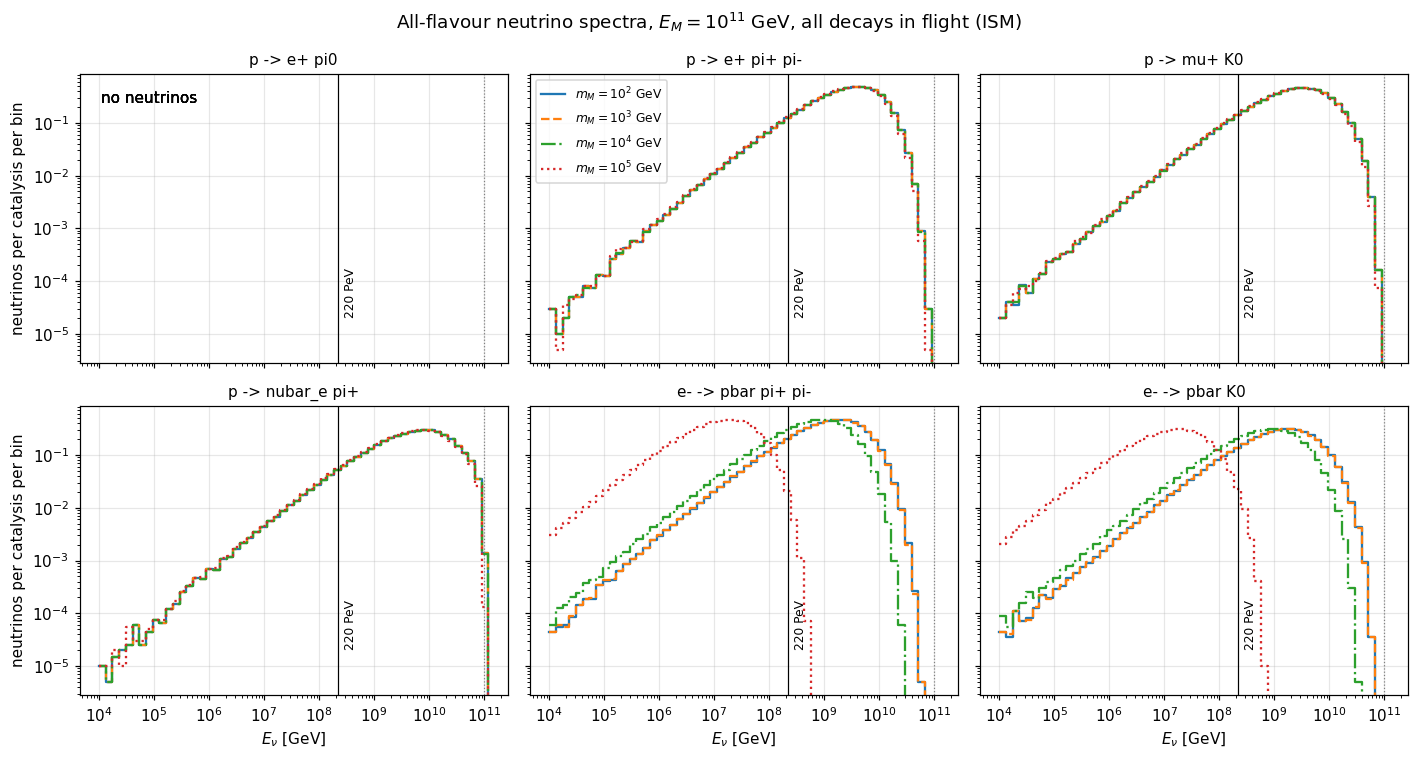

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey=True)
bins = np.logspace(4, 11.2, 60)
for ax, ch in zip(axes.flat, CH_MAIN):
    for mM, ls in zip(M_GRID, ['-', '--', '-.', ':']):
        r = bench[(ch, mM)]
        if r is None: continue
        E = r['nu']['E']
        if E.size == 0:
            ax.text(0.05, 0.9, 'no neutrinos', transform=ax.transAxes); continue
        h, _ = np.histogram(E, bins=bins)
        ax.step(bins[:-1], h / r['n'], where='post', ls=ls, label=f'$m_M=10^{{{int(np.log10(mM))}}}$ GeV')
    ax.axvline(E_KM3, color='k', lw=0.8); ax.text(E_KM3*1.3, 2e-5, '220 PeV', rotation=90, va='bottom', fontsize=8)
    ax.axvline(E_BENCH, color='gray', lw=0.8, ls=':')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_title(ch, fontsize=10); ax.grid(alpha=.3)
axes[0,1].legend(fontsize=8, loc='upper left')
for ax in axes[1]: ax.set_xlabel(r'$E_\nu$ [GeV]')
for ax in axes[:,0]: ax.set_ylabel(r'neutrinos per catalysis per bin')
fig.suptitle(r'All-flavour neutrino spectra, $E_M=10^{11}$ GeV, all decays in flight (ISM)'); fig.tight_layout()
fig.savefig('../figures/spectra_E1e11.png', dpi=150); fig.savefig('../figures/spectra_E1e11.pdf')

## 4. $E_\nu$ as a function of $E_M$ and the energy needed for a 220 PeV neutrino

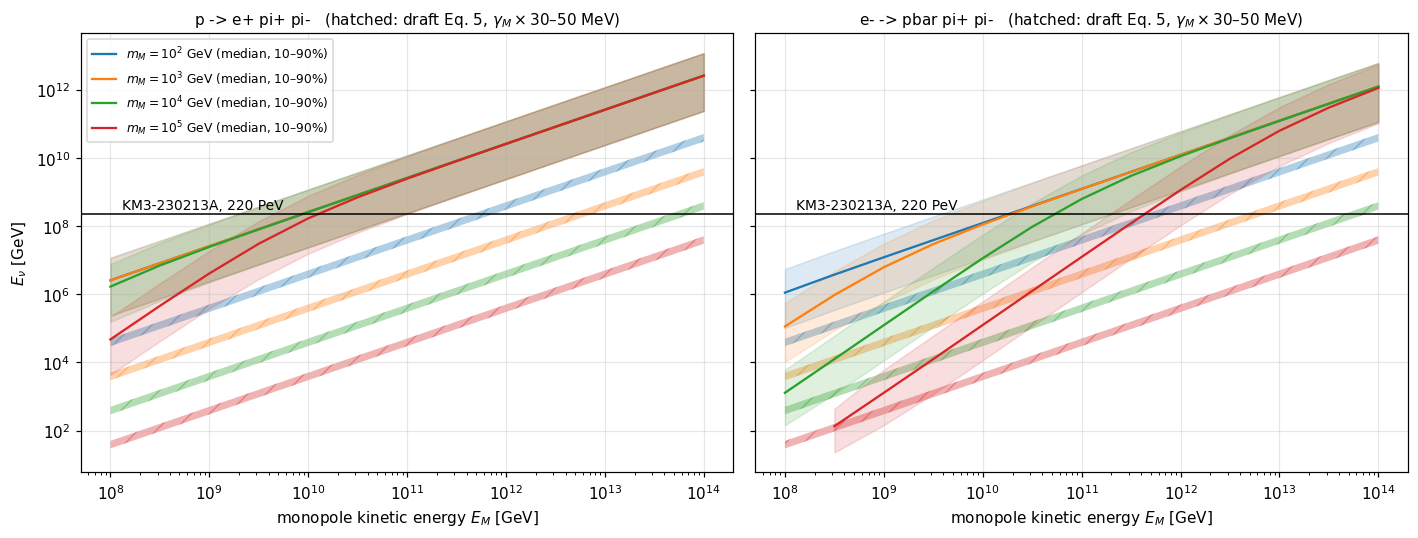

In [7]:
E_grid = np.logspace(8, 14, 13)
scan = []
for ch in CH_MAIN:
    for mM in M_GRID:
        for Ek in E_grid:
            r = mk.catalysis(ch, Ek, mM, n=N_SCAN, seed=3)
            s = mk.summarize(r)['all'] if r is not None else dict(mult=0, mean=np.nan, median=np.nan, p10=np.nan, p90=np.nan)
            scan.append(dict(channel=ch, m_M=mM, E_kin=Ek, **s))
scan = pd.DataFrame(scan); scan.to_csv('../results/scan_Enu_vs_EM.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, ch in zip(axes, ['p -> e+ pi+ pi-', 'e- -> pbar pi+ pi-']):
    for mM, c in zip(M_GRID, ['C0', 'C1', 'C2', 'C3']):
        d = scan[(scan.channel==ch) & (scan.m_M==mM)]
        ax.plot(d.E_kin, d['median'], color=c, label=f'$m_M=10^{{{int(np.log10(mM))}}}$ GeV (median, 10–90%)')
        ax.fill_between(d.E_kin, d.p10, d.p90, color=c, alpha=.15)
        lo, hi = mk.draft_estimate(d.E_kin.values, mM)
        ax.fill_between(d.E_kin, lo, hi, color=c, alpha=.35, hatch='//', lw=0)
    ax.axhline(E_KM3, color='k', lw=1); ax.text(1.3e8, E_KM3*1.4, 'KM3-230213A, 220 PeV', fontsize=9)
    ax.set_xscale('log'); ax.set_yscale('log'); ax.grid(alpha=.3)
    ax.set_xlabel(r'monopole kinetic energy $E_M$ [GeV]'); ax.set_title(ch + '   (hatched: draft Eq. 5, $\\gamma_M\\times$30–50 MeV)', fontsize=10)
axes[0].set_ylabel(r'$E_\nu$ [GeV]'); axes[0].legend(fontsize=8, loc='upper left')
fig.tight_layout(); fig.savefig('../figures/Enu_vs_EM.png', dpi=150); fig.savefig('../figures/Enu_vs_EM.pdf')

In [8]:
def required_E(d, target=E_KM3, col='median'):
    d = d.dropna(subset=[col]).sort_values('E_kin')
    if d.empty or d[col].max() < target or d[col].min() > target: return np.nan
    return 10**np.interp(np.log10(target), np.log10(d[col].values), np.log10(d.E_kin.values))
req = []
for ch in CH_MAIN:
    for mM in M_GRID:
        d = scan[(scan.channel==ch) & (scan.m_M==mM)]
        req.append(dict(channel=ch, m_M=mM,
                        E_M_for_median_220PeV=required_E(d), E_M_for_p90_220PeV=required_E(d, col='p90'),
                        E_M_for_p10_220PeV=required_E(d, col='p10'),
                        draft_E_M=(E_KM3/0.040 - 1)*mM))   # draft: gamma = 220 PeV / 40 MeV -> E_M = gamma m_M
req = pd.DataFrame(req); req.to_csv('../results/required_EM_for_220PeV.csv', index=False)
req.pivot(index='channel', columns='m_M', values=['E_M_for_median_220PeV','E_M_for_p10_220PeV','E_M_for_p90_220PeV','draft_E_M'])

E_M_for_median_220PeV                            E_M_for_p10_220PeV                            E_M_for_p90_220PeV                            draft_E_M                        
m_M                                100      1e+03    1e+04    1e+05              100      1e+03    1e+04    1e+05              100      1e+03    1e+04    1e+05     100     1e+03   1e+04   1e+05
channel                                                                                                                                                                                          
e- -> pbar K0                   1.81e+10 1.91e+10 5.32e+10 4.31e+11           2.02e+11 2.03e+11 2.77e+11 1.53e+12           3.36e+09  4.2e+09 2.01e+10 1.83e+11   5.5e+11 5.5e+12 5.5e+13 5.5e+14
e- -> pbar pi+ pi-               1.8e+10 1.91e+10 5.31e+10  4.3e+11           1.95e+11 1.96e+11  2.7e+11  1.5e+12           3.67e+09 4.54e+09 2.11e+10 1.91e+11   5.5e+11 5.5e+12 5.5e+13 5.5e+14
p -> e+ pi+ pi-                 8.59e+09 8.59e+09 8.65e+09 1.25e+10            9.3e+10  9.3e+10  9.3e+10 9.81e+10           1.88e+09 1.88e+09 1.94e+09 4.33e+09   5.5e+11 5.5e+12 5.5e+13 5.5e+14
p -> e+ pi0                          NaN      NaN      NaN      NaN                NaN      NaN      NaN      NaN                NaN      NaN      NaN      NaN   5.5e+11 5.5e+12 5.5e+13 5.5e+14
p -> mu+ K0                     9.73e+09 9.74e+09 9.79e+09 1.38e+10            1.1e+11  1.1e+11  1.1e+11 1.16e+11           1.82e+09 1.82e+09 1.88e+09 4.24e+09   5.5e+11 5.5e+12 5.5e+13 5.5e+14
p -> nubar_e pi+                4.19e+09 4.19e+09 4.25e+09 7.43e+09           5.04e+10 5.04e+10 5.05e+10  5.6e+10            7.8e+08  7.8e+08 8.35e+08  2.5e+09   5.5e+11 5.5e+12 5.5e+13 5.5e+14

`E_M_for_median_220PeV`: monopole kinetic energy at which the **median** neutrino of that channel has 220 PeV. `p10`/`p90` columns: energy at which the lower / upper decile reaches 220 PeV (i.e. the span of $E_M$ over which a 220 PeV neutrino is "typical"). `draft_E_M` is what Eq. 5 of the draft implies ($\gamma_M = 220\,{\rm PeV}/40\,{\rm MeV}$).

## 5. Atmosphere / near-detector case: prompt neutrinos only

In the atmosphere and the rock the secondaries do not decay (decay lengths $\gg$ path, Pedro 2 Nov), so only the neutrino emitted **at the vertex** counts: $p\to\bar\nu_e\pi^+$ (BR $\sim10^{-4}$, 1803.02835 / 2201.02386).

In [9]:
rows = []
for mM in M_GRID:
    r = bench[('p -> nubar_e pi+', mM)]
    s = mk.summarize(r, prompt_only=True)['nubar_e']
    rows.append(dict(m_M=mM, **s))
prompt = pd.DataFrame(rows); prompt.to_csv('../results/prompt_nubar_e_E1e11.csv', index=False)
prompt

,m_M,mult,mean,median,p10,p90
0,100,1,2.2e+10,1.58e+10,1.63e+09,5.27e+10
1,1e+03,1,2.2e+10,1.58e+10,1.63e+09,5.27e+10
2,1e+04,1,2.19e+10,1.58e+10,1.63e+09,5.27e+10
3,1e+05,1,2.08e+10,1.5e+10,1.55e+09,5.01e+10


## 6. Sensitivity to the two modelling choices

* the invariant mass of the light system ($Q_{\max}$ = 0.3, 1, 3 GeV),
* the CM angular distribution: isotropic (lowest partial wave) versus a forward-peaked toy ($\cos\theta_{cm}$ fixed at 0.9) to show how much the answer depends on the monopole being deflected.

In [10]:
rows = []
ch, mM = 'e- -> pbar pi+ pi-', 1e3
for Q in (0.3, 1.0, 3.0):
    s = mk.summarize(mk.catalysis(ch, E_BENCH, mM, n=N_SCAN, Q_max=Q, seed=5))['all']
    rows.append(dict(variant=f'isotropic, Q_max={Q} GeV', **s))
for c in (0.0, 0.9, 0.99):
    s = mk.summarize(mk.catalysis(ch, E_BENCH, mM, n=N_SCAN, cos_theta_cm=c, seed=5))['all']
    rows.append(dict(variant=f'fixed cos(theta_cm)={c}', **s))
ch = 'p -> e+ pi+ pi-'
for Q in (0.3, 1.0, 3.0):
    s = mk.summarize(mk.catalysis(ch, E_BENCH, mM, n=N_SCAN, Q_max=Q, seed=5))['all']
    rows.append(dict(variant=f'[{ch}] isotropic, Q_max={Q} GeV', **s))
sens = pd.DataFrame(rows); sens

,variant,mult,mean,median,p10,p90
0,"isotropic, Q_max=0.3 GeV",6,1.77e+09,1.04e+09,1.04e+08,4.36e+09
1,"isotropic, Q_max=1.0 GeV",6,2.31e+09,1.2e+09,1.09e+08,5.88e+09
2,"isotropic, Q_max=3.0 GeV",6,2.97e+09,1.41e+09,1.12e+08,7.82e+09
3,fixed cos(theta_cm)=0.0,6,2.32e+09,1.55e+09,2.41e+08,5.42e+09
4,fixed cos(theta_cm)=0.9,6,2.32e+08,1.55e+08,2.41e+07,5.42e+08
5,fixed cos(theta_cm)=0.99,6,2.32e+07,1.55e+07,2.41e+06,5.42e+07
6,"[p -> e+ pi+ pi-] isotropic, Q_max=0.3 GeV",6,5.07e+09,3.16e+09,3.2e+08,1.25e+10
7,"[p -> e+ pi+ pi-] isotropic, Q_max=1.0 GeV",6,4.55e+09,2.53e+09,2.34e+08,1.16e+10
8,"[p -> e+ pi+ pi-] isotropic, Q_max=3.0 GeV",6,4.22e+09,2.13e+09,1.71e+08,1.11e+10


## 7. Verification

1. energy conservation at the vertex;  
2. Candela et al. Fig. 2: $M e^-\to M\bar p$ at $\theta_{cm}=0$ gives $p_{\bar p}\to 861.4$ GeV for any $m_M$;  
3. heavy-monopole limit: $\langle E_W^{\rm lab}\rangle = \gamma_M^2 m_p$;  
4. $\sqrt s$ independent of $m_M$ while $m_M^2 \ll 2E_M m_t$;  
5. stopped secondaries (solar-core case) reproduce the 29.79 MeV $\nu_\mu$ line and the Michel spectrum (mean 31.7 MeV for $\nu_e$, endpoint 52.8 MeV) — this is the regime of the draft's Eq. 5.

In [11]:
r = mk.catalysis('p -> e+ pi+ pi-', E_BENCH, 1e3, n=50_000)
print('1. max |E_M\'+E_W-E_tot|/E_tot =', np.max(np.abs(r['EM_lab']+r['EW_lab']-r['frame']['E_tot'])/r['frame']['E_tot']))
for mM, E in ((1e3, 1.89e12), (1e9, 1e14)):
    rr = mk.catalysis('e- -> pbar', E-mM, mM, n=3, Q_max=0, cos_theta_cm=1.0)
    print(f'2. m_M={mM:.0e}: p_pbar(theta_cm=0) = {np.sqrt(rr["EW_lab"][0]**2-mp**2):.1f} GeV (Candela: 861.4)')
g = 11.0; rr = mk.catalysis('p -> e+ pi+ pi-', (g-1)*1e16, 1e16, n=50_000)
print(f'3. gamma_M={g}: <E_W,lab> = {rr["EW_lab"].mean():.1f} GeV,  gamma_M^2 m_p = {g*g*mp:.1f} GeV')
print('4. sqrt(s) for m_M = 1e2..1e5 GeV at E_M=1e11:', [f"{mk.cm_frame(E_BENCH, m, mp)['sqrt_s']:.4g}" for m in M_GRID])
rr = mk.catalysis('p -> e+ pi+ pi-', 0.5e-6*1e16, 1e16, n=50_000, decay_at_rest=True)
nu = rr['nu']
sel = (nu['flavour']=='nu_mu') & (nu['gen']==1); print(f"5. stopped pi+: nu_mu = {nu['E'][sel].mean()*1e3:.2f} +- {nu['E'][sel].std()*1e3:.2f} MeV (29.79)")
sel = nu['flavour']=='nu_e'; print(f"   stopped mu+: nu_e mean {nu['E'][sel].mean()*1e3:.1f} MeV, endpoint {nu['E'][sel].max()*1e3:.1f} MeV (31.7, 52.8)")

1. max |E_M'+E_W-E_tot|/E_tot = 4.577636672930683e-16
2. m_M=1e+03: p_pbar(theta_cm=0) = 861.4 GeV (Candela: 861.4)
2. m_M=1e+09: p_pbar(theta_cm=0) = 861.5 GeV (Candela: 861.4)
3. gamma_M=11.0: <E_W,lab> = 113.5 GeV,  gamma_M^2 m_p = 113.5 GeV
4. sqrt(s) for m_M = 1e2..1e5 GeV at E_M=1e11: ['4.332e+05', '4.332e+05', '4.333e+05', '4.446e+05']
5. stopped pi+: nu_mu = 29.79 +- 0.00 MeV (29.79)
   stopped mu+: nu_e mean 31.7 MeV, endpoint 52.8 MeV (31.7, 52.8)


## 8. What this means for the draft

* Eq. 5 ($\gamma_M = E_\nu/E_\nu^{(0)}$ with $E_\nu^{(0)}=30$–$50$ MeV) is the $\beta_M\to0$ (solar-core) result. For a relativistic monopole lighter than $\sqrt{2E_Mm_p}$ the products share the **centre-of-mass** energy, and after the isotropic CM scattering each neutrino carries a few per cent of $E_M$ (see the tables above). The neutrino energy is then set by $E_M$ alone, not by $\gamma_M$: the requirement for KM3-230213A becomes a requirement on the monopole **energy**, and the mass enters only through what energy the magnetic fields can give it (Perri et al. 2025) and through the suppression $\xi=(m_p/m_M)^2$ of the proton channels.
* In the atmosphere only the prompt $\bar\nu_e$ of $p\to\bar\nu_e\pi^+$ survives (BR $\sim10^{-4}$); its energy is in Sect. 5.
* In the ISM every channel with a charged pion or a kaon gives 3–6 neutrinos per catalysis with energies of order $10^{-2}E_M$; the required $E_M$ for 220 PeV is in Sect. 4.
* Open modelling choices (to agree with Daniele/Pedro/Michele): invariant mass of the light system, and whether the CM angular distribution of the full inclusive process stays isotropic at these energies.